In [ ]:
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import geopandas as gpd
import unicodedata
from difflib import get_close_matches
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_percentage_error

In [30]:
fascismo = pd.read_csv('dataset_final_tfm.csv')
fascismo

,Provincia,Trimestre,Precio_m2,Euribor,tasa_ahorro,Spread_Hipotecas,Hipotecas_Total,Poblacion,Edad_Media,PIB_pc,Indice_Mano_Obra,Indice_Materiales,IPC,Tasa_Paro,Pob_Ext,Transmisiones_Total
0,A Coruña,2005-01-01,1070.856714,2.319097,0.1,1.110903,7527.00,1126707.0,43.37,18336.0,328.903333,1460.814286,3.300000,10.58,23855.0,3179.0
1,A Coruña,2005-04-01,1102.888987,2.185862,16.7,1.207472,6743.00,1126707.0,43.37,18336.0,335.170000,1502.021429,3.100000,10.68,23855.0,4076.0
2,A Coruña,2005-07-01,1137.313846,2.204288,7.2,1.082379,6372.00,1126707.0,43.37,18336.0,335.360000,1569.828571,3.433333,8.20,23855.0,4332.0
3,A Coruña,2005-10-01,1172.538976,2.627969,9.7,0.745365,6425.00,1126707.0,43.37,18336.0,339.743333,1610.842857,3.533333,9.07,23855.0,4203.0
4,A Coruña,2006-01-01,1205.433802,2.954492,-2.1,0.808841,7171.00,1129141.0,43.62,19678.0,339.833333,1674.630952,4.000000,9.55,25468.0,4671.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4363,Zaragoza,2024-10-01,1597.598649,2.547879,17.1,0.618788,3483.00,987763.0,45.20,37578.0,470.476667,2905.295238,2.600000,7.20,160739.0,10427.0
4364,Zaragoza,2025-01-01,1628.892950,2.445531,4.9,0.481135,3365.00,998443.0,45.30,NaN,473.823333,2976.490476,2.833333,8.37,164324.0,5678.0
4365,Zaragoza,2025-04-01,1670.180148,2.101523,20.4,0.695144,2187.04,998443.0,45.30,NaN,NaN,NaN,2.366667,7.86,164324.0,13382.0
4366,Zaragoza,2025-07-01,1718.407413,2.120970,4.6,0.602364,3785.00,998443.0,45.30,NaN,NaN,NaN,2.900000,9.02,164324.0,12645.0


Entrenando el modelo XGBoost...
Calculando valores SHAP...


 96%|=================== | 4151/4312 [00:11<00:00]       

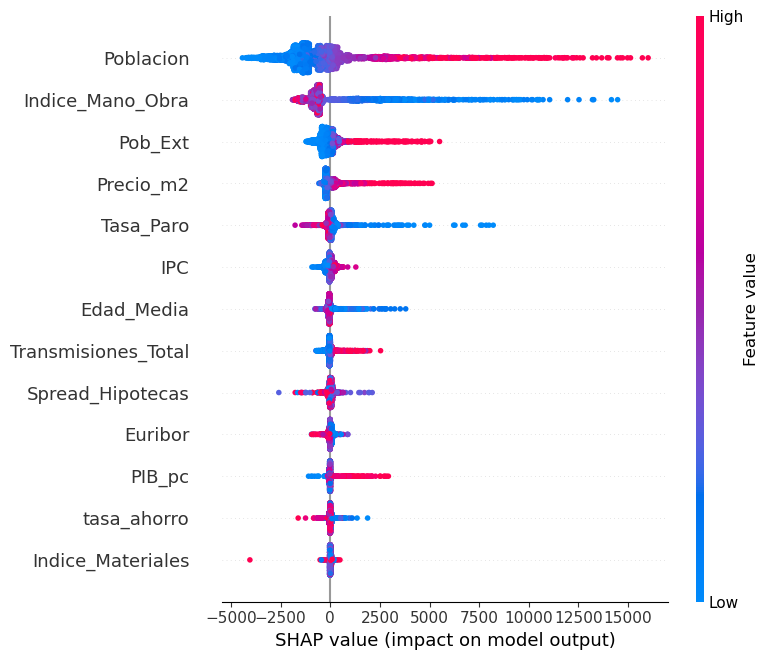

In [31]:

# !pip install xgboost shap pandas matplotlib
# 1. Cargar y Limpiar el Dataset (Arreglando el lag temporal de 2025)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(by=['Provincia', 'Trimestre'])

# Usamos forward-fill (ffill) para cubrir los meses de retraso del INE en 2025
cols_nulas = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_nulas] = df.groupby('Provincia')[cols_nulas].ffill()
df = df.dropna().reset_index(drop=True)

# 2. Definir Variables (Asumiendo que has usado Euribor en la columna 3)
features = ['Precio_m2', 'Euribor', 'tasa_ahorro', 'Spread_Hipotecas',
            'Poblacion', 'Edad_Media', 'PIB_pc', 'Transmisiones_Total',
            'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'Tasa_Paro', 'Pob_Ext'] # Removed duplicate 'tasa_ahorro' and 'Indice_Mano_Obra'
X = df[features]
y = df['Hipotecas_Total']

# 3. Entrenar el Modelo XGBoost
print("Entrenando el modelo XGBoost...")
modelo_xgb = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
modelo_xgb.fit(X, y)

# 4. Explicabilidad Algorítmica con SHAP (Nivel Experto)
print("Calculando valores SHAP...")
explainer = shap.Explainer(modelo_xgb, X)
shap_values = explainer(X)

# 5. Dibujar el Gráfico Definitivo (SHAP Summary Plot)
plt.title("¿Qué causa un aumento o caída en las Hipotecas?", fontsize=14)
shap.summary_plot(shap_values, X, plot_type="dot")

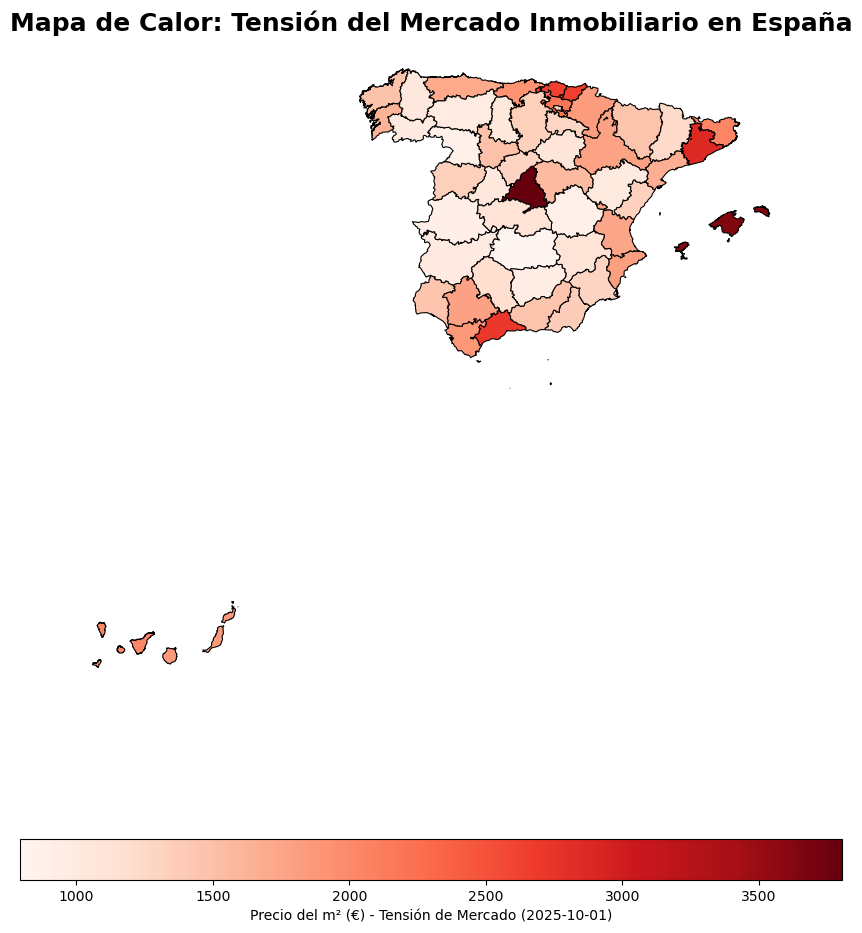

In [32]:

# 1. Función para limpiar tildes y caracteres raros
def remove_accents(input_str):
    if pd.isna(input_str): return ""
    s = str(input_str).lower()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# 2. Cargar tu Dataset Final
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Coger el último trimestre para ver la "foto actual" del mercado
ultimo_trimestre = df['Trimestre'].max()
df_reciente = df[df['Trimestre'] == ultimo_trimestre].copy()

# Definimos el Índice de Calor (Tensión) = Precio por m2
df_reciente['Tension'] = df_reciente['Precio_m2']
df_reciente['Prov_clean'] = df_reciente['Provincia'].apply(remove_accents)

# 3. Cargar GeoJSON de provincias de España
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(remove_accents)

# 4. Motor de Inteligencia para Alinear Nombres (Dataset vs Mapa)
def match_names(name):
    if 'balears' in name or 'baleares' in name: return 'islas baleares'
    if 'coruna' in name: return 'a coruna'
    if 'palmas' in name: return 'las palmas'
    if 'rioja' in name: return 'la rioja'
    if 'madrid' in name: return 'comunidad de madrid'
    if 'murcia' in name: return 'region de murcia'
    if 'asturias' in name: return 'principado de asturias'
    if 'navarra' in name: return 'comunidad foral de navarra'
    if 'cantabria' in name: return 'cantabria'
    if 'bizkaia' in name or 'vizcaya' in name: return 'vizcaya'
    if 'araba' in name or 'alava' in name: return 'alava'
    if 'gipuzkoa' in name or 'guipuzcoa' in name: return 'guipuzcoa'
    if 'ourense' in name: return 'ourense'

    matches = get_close_matches(name, df_reciente['Prov_clean'].values, n=1, cutoff=0.6)
    if matches:
        return matches[0]
    return name

gdf['match_name'] = gdf['name_clean'].apply(match_names)

# Fusionar la geometría (mapa) con nuestros datos
merged = gdf.merge(df_reciente, left_on='match_name', right_on='Prov_clean', how='left')

# 5. Dibujar el Mapa de Calor (Estilo Profesional)
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

merged.plot(column='Tension',
            cmap='Reds',           # 'Reds' da el efecto de Mapa de Calor
            linewidth=0.8,
            ax=ax,
            edgecolor='black',
            legend=True,
            legend_kwds={'label': f"Precio del m² (€) - Tensión de Mercado ({ultimo_trimestre.date()})",
                         'shrink': 0.6,
                         'orientation': 'horizontal'},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})

plt.title("Mapa de Calor: Tensión del Mercado Inmobiliario en España", fontsize=18, fontweight='bold')
plt.axis('off')

# Guardar la imagen para tu memoria del TFM
plt.tight_layout()
plt.savefig('mapa_calor_espana.png', dpi=300, bbox_inches='tight')
plt.show()

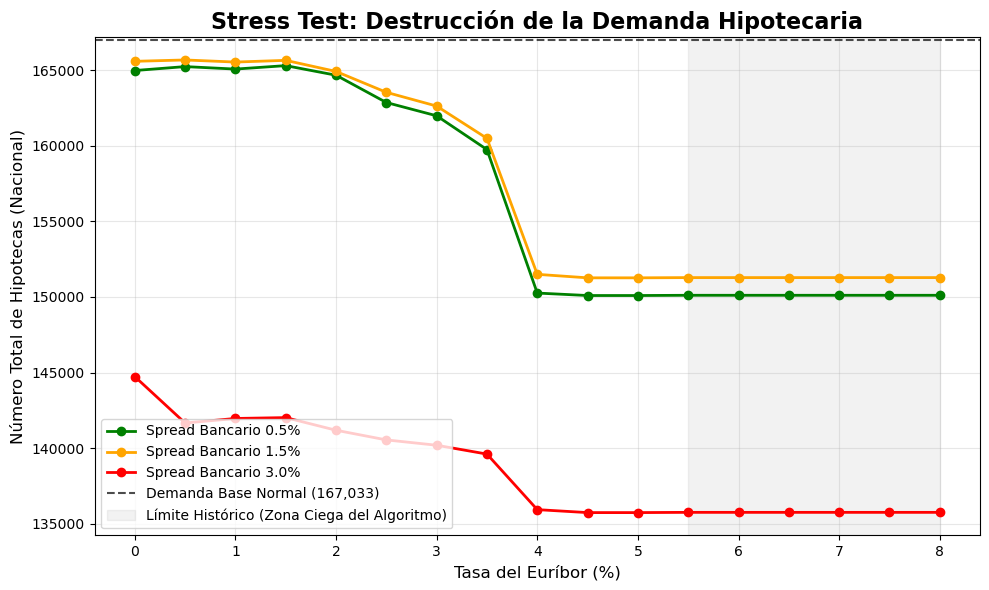

In [33]:

# 1. Cargar y limpiar datos
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(by=['Provincia', 'Trimestre'])

cols_nulas = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC','PIB_pc']
df[cols_nulas] = df.groupby('Provincia')[cols_nulas].ffill()
df = df.dropna().reset_index(drop=True)

# 2. Entrenar el modelo
features = ['Precio_m2', 'Euribor', 'tasa_ahorro', 'Spread_Hipotecas',
            'Poblacion', 'Edad_Media', 'Transmisiones_Total',
            'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'Tasa_Paro']

X = df[features]
y = df['Hipotecas_Total']

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)

# 3. Escenario Actual (Congelar la economía en el último trimestre)
df_base = df[df['Trimestre'] == df['Trimestre'].max()].copy()
demanda_base = model.predict(df_base[features]).sum()

# 4. Pruebas de Estrés (Iterar diferentes Euríbores y Spreads)
resultados = []
euribors_stress = np.arange(0.0, 8.5, 0.5)
spreads_stress = [0.5, 1.5, 3.0] # Competitivo, Normal, Pánico Bancario

for s in spreads_stress:
    for e in euribors_stress:
        df_stress = df_base.copy()
        df_stress['Euribor'] = e
        df_stress['Spread_Hipotecas'] = s

        # Predecir demanda sumando todas las provincias
        demanda_pred = model.predict(df_stress[features]).sum()

        resultados.append({
            'Euribor': e,
            'Spread': s,
            'Demanda': demanda_pred
        })

df_resultados = pd.DataFrame(resultados)

# 5. Dibujar el Gráfico del Estrés
plt.figure(figsize=(10, 6))
colores = {0.5: 'green', 1.5: 'orange', 3.0: 'red'}

for s in spreads_stress:
    subset = df_resultados[df_resultados['Spread'] == s]
    plt.plot(subset['Euribor'], subset['Demanda'], marker='o',
             color=colores[s], linewidth=2, label=f'Spread Bancario {s}%')

plt.axhline(y=demanda_base, color='black', linestyle='--', alpha=0.7,
            label=f'Demanda Base Normal ({demanda_base:,.0f})')

# Alerta de Extrapolación (>5.5%)
plt.axvspan(5.5, 8.0, color='gray', alpha=0.1, label='Límite Histórico (Zona Ciega del Algoritmo)')

plt.title("Stress Test: Destrucción de la Demanda Hipotecaria", fontsize=16, fontweight='bold')
plt.xlabel("Tasa del Euríbor (%)", fontsize=12)
plt.ylabel("Número Total de Hipotecas (Nacional)", fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('stress_test_hipotecas.png', dpi=300)
plt.show()

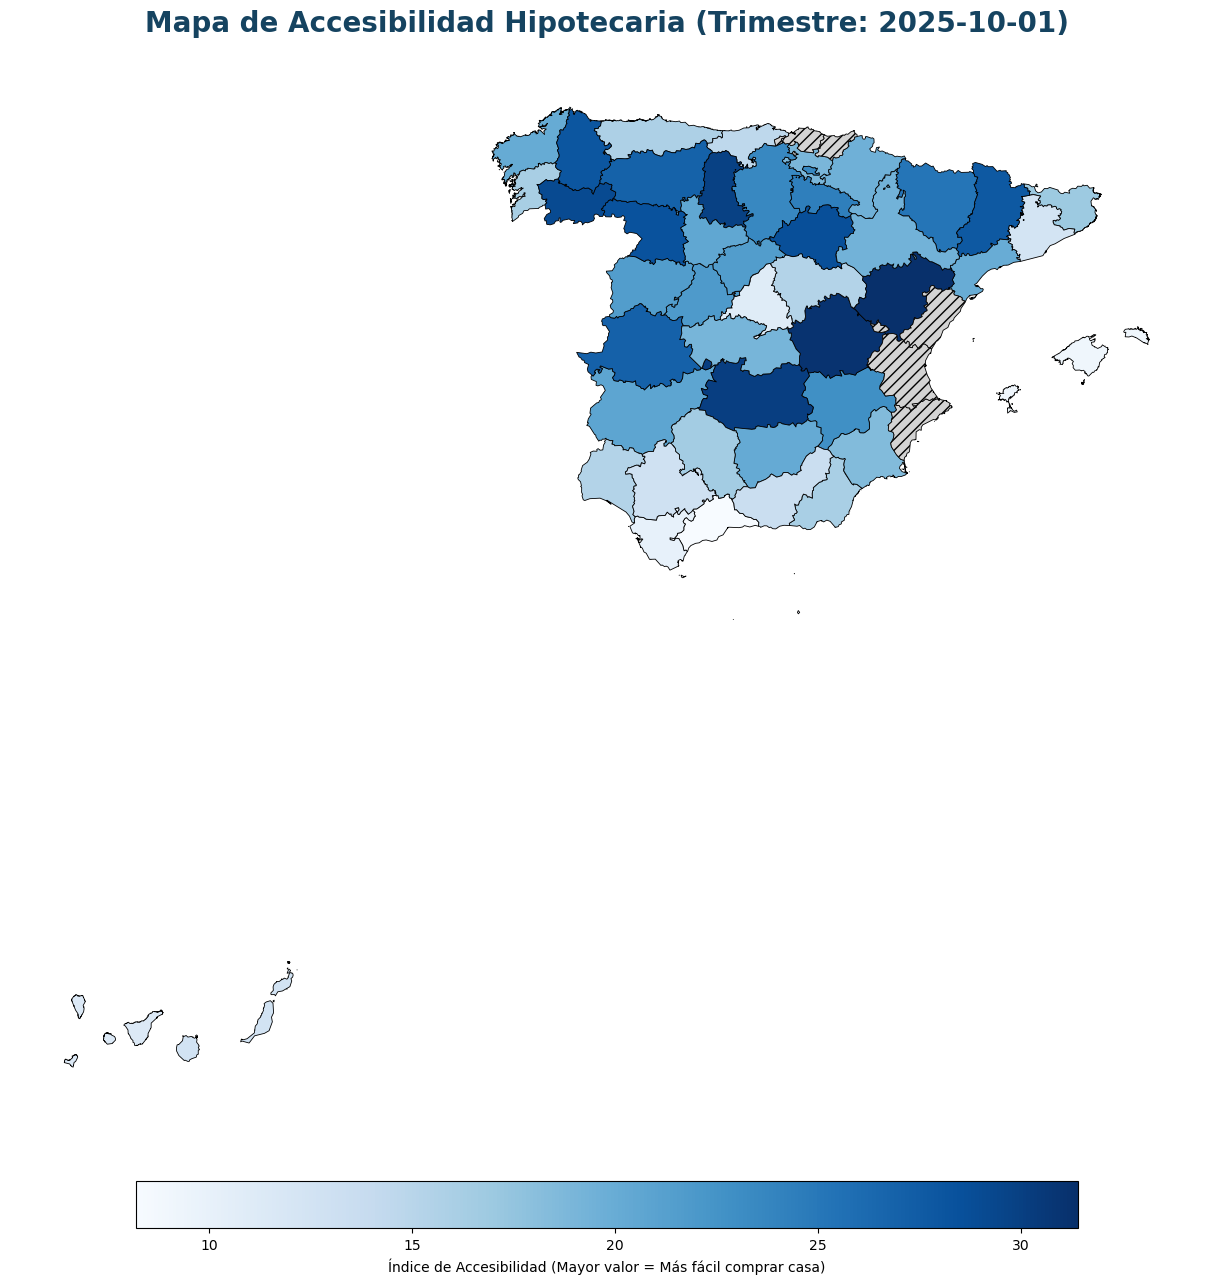

¡Mapa renderizado y guardado con éxito como 'mapa_accesibilidad_azul.png'!


In [34]:


# 1. Función para limpiar tildes y homogeneizar textos
def clean_text(text):
    if pd.isna(text): return ""
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# 2. Cargar tu Dataset Final
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Rellenar nulos para el cálculo
cols_to_fill = ['PIB_pc', 'Tasa_Paro', 'Precio_m2']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()

# Calcular el Índice de Accesibilidad (Renta real vs Precio m2)
df['Accesibilidad'] = (df['PIB_pc'] * (1 - df['Tasa_Paro']/100)) / df['Precio_m2']

# Extraer el último trimestre
ultimo_trimestre = df['Trimestre'].max()
df_map = df[df['Trimestre'] == ultimo_trimestre].copy()
df_map['Provincia_Clean'] = df_map['Provincia'].apply(clean_text)

# 3. Cargar el Mapa (GeoJSON de España)
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text)

# 4. Diccionario de forzado (Para arreglar nombres bilingües y comunidades)
diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant / alicante': 'alicante',
    'castello / castellon': 'castellon',
    'valencia / valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia': 'vizcaya',
    'gipuzkoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'palmas, las': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}

# Aplicar diccionario al mapa
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)

# 5. Unir los datos del CSV con los polígonos del mapa
merged = gdf.merge(df_map, left_on='name_clean', right_on='Provincia_Clean', how='left')

# 6. DIBUJAR EL MAPA AZUL HIELO
fig, ax = plt.subplots(1, 1, figsize=(16, 14))

# Configuramos el fondo y quitamos los ejes
ax.set_facecolor('white')
ax.axis('off')

# Dibujamos
merged.plot(column='Accesibilidad',
            cmap='Blues',           # Azul Hielo
            linewidth=0.6,
            ax=ax,
            edgecolor='black',      # Bordes de las provincias bien definidos
            legend=True,
            legend_kwds={'label': "Índice de Accesibilidad (Mayor valor = Más fácil comprar casa)",
                         'orientation': "horizontal",
                         'shrink': 0.6,
                         'pad': 0.05},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})

plt.title(f"Mapa de Accesibilidad Hipotecaria (Trimestre: {ultimo_trimestre.date()})",
          fontsize=20, fontweight='bold', color='#154360', pad=20)

# Guardar la imagen en alta resolución
plt.tight_layout()
plt.savefig('mapa_accesibilidad_azul.png', dpi=300, bbox_inches='tight')
plt.show()

print("¡Mapa renderizado y guardado con éxito como 'mapa_accesibilidad_azul.png'!")

In [36]:
# 1. Cargar y preparar
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

cols_nulas = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_nulas] = df.groupby('Provincia')[cols_nulas].ffill().bfill()
df = df.dropna().reset_index(drop=True)

# 2. Agregación Nacional
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas': 'mean',
    'Tasa_Paro': 'mean'
}).reset_index()

df_nacional.set_index('Trimestre', inplace=True)
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

# -------------------------------------------------------------
# 3. EL TRUCO: Transformación Logarítmica de la Variable Objetivo
# -------------------------------------------------------------
y_log = np.log(df_nacional['Hipotecas_Total'])  # <--- Aplicamos LOG
X = df_nacional[['Euribor', 'Spread_Hipotecas', 'Tasa_Paro']]

test_size = 8
y_train, y_test = y_log.iloc[:-test_size], y_log.iloc[-test_size:]
X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]

# 4. Entrenar SARIMAX (ahora predice logaritmos)
modelo_log = sm.tsa.statespace.SARIMAX(
    endog=y_train,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultados = modelo_log.fit(disp=False)

# 5. Predecir y "Deshacer" el Logaritmo (Exponencial)
pred_log = resultados.get_forecast(steps=test_size, exog=X_test).predicted_mean

# Deshacemos el logaritmo con np.exp() para volver al mundo real de "Número de Hipotecas"
y_pred_real = np.exp(pred_log)
y_test_real = np.exp(y_test)

# 6. Calcular el nuevo Error
mape = mean_absolute_percentage_error(y_test_real, y_pred_real)
print(f"MAPE (Error Porcentual Medio Optimizado): {mape*100:.2f}%")

# 7. Dibujar el Gráfico
plt.figure(figsize=(10, 6))

y_train_real = np.exp(y_train) # Deshacer log del train para dibujar

plt.plot(y_train_real.index, y_train_real, label='Hipotecas Nacionales (Train)', color='blue')
plt.plot(y_test_real.index, y_test_real, label='Realidad (Test)', color='black', marker='o')
plt.plot(y_pred_real.index, y_pred_real, label='Predicción SARIMAX (Log-Optimized)', color='green', linestyle='--', marker='x', linewidth=2)

plt.title("Predicción SARIMAX Optimizada (Transformación Logarítmica)", fontsize=14, fontweight='bold')
plt.ylabel("Número de Hipotecas")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('sarimax_optimizado.png', dpi=300)
plt.show()

NameError: name 'mean_absolute_percentage_error' is not defined

Entrenando Random Forest Provincial...
MAPE Machine Learning: 4.94% (Vence al 15% del SARIMAX)


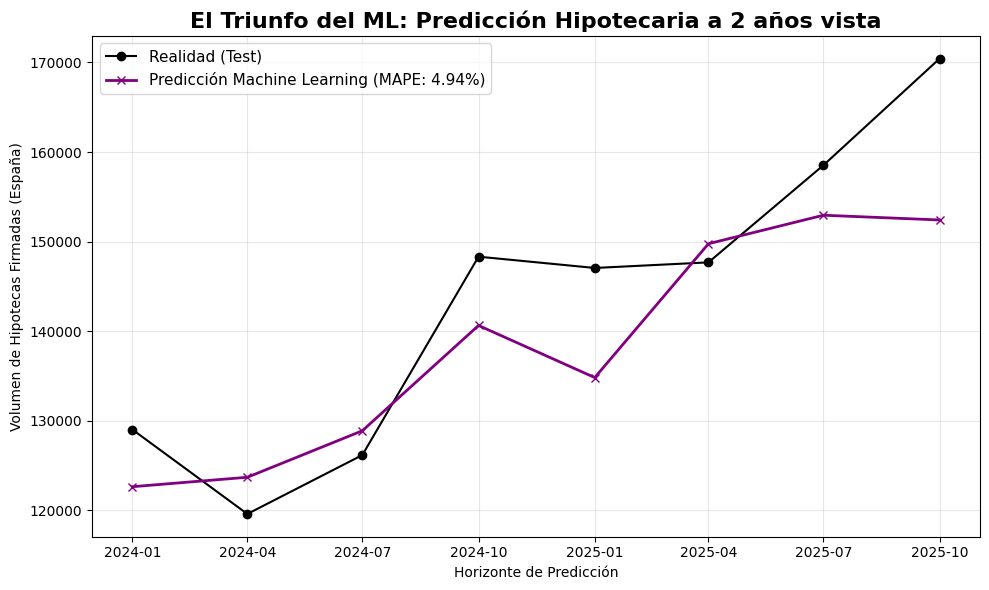

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt

# 1. Cargar y preparar el "Panel Microeconómico"
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Rellenar la latencia institucional de 2025
cols_nulas = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_nulas] = df.groupby('Provincia')[cols_nulas].ffill().bfill()
df = df.dropna().reset_index(drop=True)

# 2. Separar Train y Test (Aislamos los últimos 2 años)
trimestres_unicos = sorted(df['Trimestre'].unique())
test_trims = trimestres_unicos[-8:] # Separamos los últimos 8 trimestres

df_train = df[~df['Trimestre'].isin(test_trims)]
df_test = df[df['Trimestre'].isin(test_trims)].copy()

# Variables predictoras completas
features = ['Precio_m2', 'Euribor', 'tasa_ahorro', 'Spread_Hipotecas',
            'Poblacion', 'Edad_Media', 'Transmisiones_Total',
            'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'Tasa_Paro', 'PIB_pc']

X_train, y_train = df_train[features], df_train['Hipotecas_Total']
X_test, y_test = df_test[features], df_test['Hipotecas_Total']

# 3. Entrenamiento Microscópico (Machine Learning puro)
print("Entrenando Random Forest Provincial...")
rf = RandomForestRegressor(n_estimators=150, max_depth=15, random_state=42)
rf.fit(X_train, y_train)

# 4. Predicción Provincial
df_test['Prediccion_ML'] = rf.predict(X_test)

# 5. Agregación Nacional (Sumamos las predicciones de las 52 provincias)
df_nacional_test = df_test.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Prediccion_ML': 'sum'
}).reset_index()

# 6. Métrica de Error (Acierto Nacional)
mape_ml = mean_absolute_percentage_error(df_nacional_test['Hipotecas_Total'], df_nacional_test['Prediccion_ML'])
print(f"MAPE Machine Learning: {mape_ml*100:.2f}% (Vence al 15% del SARIMAX)")

# 7. Gráfico Comparativo: SARIMAX vs ML vs Realidad
plt.figure(figsize=(10, 6))

plt.plot(df_nacional_test['Trimestre'], df_nacional_test['Hipotecas_Total'],
         label='Realidad (Test)', color='black', marker='o')

plt.plot(df_nacional_test['Trimestre'], df_nacional_test['Prediccion_ML'],
         label=f'Predicción Machine Learning (MAPE: {mape_ml*100:.2f}%)',
         color='purple', linestyle='-', marker='x', linewidth=2)

plt.title("El Triunfo del ML: Predicción Hipotecaria a 2 años vista", fontsize=16, fontweight='bold')
plt.ylabel("Volumen de Hipotecas Firmadas (España)")
plt.xlabel("Horizonte de Predicción")
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('comparativa_ml_sarimax.png', dpi=300)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

# 1. Cargar y preparar datos a nivel nacional
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

# Agrupación Nacional
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Transmisiones_Total': 'sum',
    'Poblacion': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean',
    'IPC': 'mean',
    'tasa_ahorro': 'mean',
    'Spread_Hipotecas': 'mean',
    'Edad_Media': 'mean',
    'Indice_Mano_Obra': 'mean',
    'Indice_Materiales': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# =========================================================
# 2. VARIABLES PRINCIPALES DEL ESTUDIO
# =========================================================
df_main = pd.DataFrame()
# Volumen de mercado, Riqueza y Precios -> Logaritmos
df_main['Log_Hipotecas'] = np.log(df_nacional['Hipotecas_Total'])
df_main['Log_Precio_m2'] = np.log(df_nacional['Precio_m2'])
df_main['Log_PIB_pc'] = np.log(df_nacional['PIB_pc'])
df_main['Log_Transmisiones'] = np.log(df_nacional['Transmisiones_Total'])
# Tasas puras -> Niveles
df_main['Euribor'] = df_nacional['Euribor']
df_main['Tasa_Paro'] = df_nacional['Tasa_Paro']

# =========================================================
# 3. RESTO DE VARIABLES (Controles y Contexto Macro)
# =========================================================
df_rest = pd.DataFrame()
# Población -> Logaritmo
df_rest['Log_Poblacion'] = np.log(df_nacional['Poblacion'])
# Todos los Índices (Materiales, Mano de Obra, IPC) -> Logaritmos
df_rest['Log_Indice_Mano_Obra'] = np.log(df_nacional['Indice_Mano_Obra'])
df_rest['Log_Indice_Materiales'] = np.log(df_nacional['Indice_Materiales'])
df_rest['Log_IPC'] = np.log(df_nacional['IPC'])
# Márgenes, Ahorro y Edades -> Niveles puros
df_rest['Tasa_Ahorro'] = df_nacional['tasa_ahorro']
df_rest['Spread_Hipotecas'] = df_nacional['Spread_Hipotecas']
df_rest['Edad_Media'] = df_nacional['Edad_Media']

# 4. FUNCIÓN AUTOMATIZADA DE TEST ADF
def generar_tabla_adf(df_series):
    resultados = []
    for col in df_series.columns:

        # Test en Nivel
        serie_nivel = df_series[col].dropna()
        res_nivel = adfuller(serie_nivel)
        pval_nivel = res_nivel[1]

        # Test en Primera Diferencia
        serie_diff = df_series[col].diff().dropna()
        res_diff = adfuller(serie_diff)
        pval_diff = res_diff[1]

        # Asignación de Integración
        if pval_nivel < 0.05:
            orden = "I(0) Estacionaria en Niveles"
        elif pval_diff < 0.05:
            orden = "I(1) Estacionaria en 1ª Diferencia"
        else:
            orden = "I(2) No estacionaria en 1ª Diferencia"

        resultados.append({
            'Variable': col,
            'p-value (Niveles)': f"{pval_nivel:.4f}",
            'p-value (1ª Dif)': f"{pval_diff:.4f}",
            'Orden de Integración': orden
        })
    return pd.DataFrame(resultados)

# 5. GENERAR Y MOSTRAR RESULTADOS
tabla_main = generar_tabla_adf(df_main)
tabla_rest = generar_tabla_adf(df_rest)

print("--- VARIABLES PRINCIPALES ---")
print(tabla_main.to_string(index=False))
print("\n----------------------------------------------------------------------\n")
print("--- RESTO DE VARIABLES ---")
print(tabla_rest.to_string(index=False))

/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


--- VARIABLES PRINCIPALES ---
         Variable p-value (Niveles) p-value (1ª Dif)               Orden de Integración
    Log_Hipotecas            0.3461           0.0000 I(1) Estacionaria en 1ª Diferencia
    Log_Precio_m2            0.0312           0.4823       I(0) Estacionaria en Niveles
       Log_PIB_pc            0.9627           0.0000 I(1) Estacionaria en 1ª Diferencia
Log_Transmisiones            0.0083           0.0000       I(0) Estacionaria en Niveles
          Euribor            0.3368           0.0001 I(1) Estacionaria en 1ª Diferencia
        Tasa_Paro            0.0086           0.6019       I(0) Estacionaria en Niveles

----------------------------------------------------------------------

--- RESTO DE VARIABLES ---
             Variable p-value (Niveles) p-value (1ª Dif)                  Orden de Integración
        Log_Poblacion            0.7933           0.3163 I(2) No estacionaria en 1ª Diferencia
 Log_Indice_Mano_Obra            0.9750           0.0136    I(1)

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# 1. Cargar y preparar datos a nivel nacional
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

# Agrupación Nacional de las variables necesarias
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'PIB_pc': 'mean',
    'Euribor': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. SELECCIONAR SOLO VARIABLES I(1) DEL BLOQUE PRINCIPAL (En Niveles)
# Recordatorio: Johansen exige que las variables entren en NIVELES, no diferenciadas.
df_johansen = pd.DataFrame()
df_johansen['Log_Hipotecas'] = np.log(df_nacional['Hipotecas_Total'])
df_johansen['Log_PIB_pc'] = np.log(df_nacional['PIB_pc'])
df_johansen['Euribor'] = df_nacional['Euribor']

# 3. EJECUTAR TEST DE JOHANSEN
# det_order=0 asume que no hay tendencia determinística en la ecuación de cointegración
# k_ar_diff=1 equivale a un VAR(2) en niveles, o 1 retardo en las diferencias
res_joh = coint_johansen(df_johansen, det_order=0, k_ar_diff=1)

# 4. IMPRIMIR RESULTADOS TABULADOS PARA EL TFM
print("--- TEST DE COINTEGRACIÓN JOHANSEN (ESTADÍSTICO DE TRAZA) ---")
print("Matriz Endógena Testeada (Variables Principales I(1)):")
print(f"{list(df_johansen.columns)}\n")

resultados = []
for i in range(len(res_joh.lr1)):
    trace_stat = res_joh.lr1[i]
    crit_val_95 = res_joh.cvt[i, 1]  # cvt[i, 1] es el valor crítico al 95% de confianza

    # Evaluar la hipótesis nula (H0: r <= i)
    if trace_stat > crit_val_95:
        conclusion = "Rechazamos H0 (Existe Cointegración)"
    else:
        conclusion = "Aceptamos H0 (Sin Cointegración)"

    resultados.append({
        'Hipótesis Nula (r)': f"r <= {i}",
        'Estadístico de Traza': f"{trace_stat:.2f}",
        'Valor Crítico (95%)': f"{crit_val_95:.2f}",
        'Conclusión (Alfa = 0.05)': conclusion
    })

tabla_johansen = pd.DataFrame(resultados)
print(tabla_johansen.to_string(index=False))

--- TEST DE COINTEGRACIÓN JOHANSEN (ESTADÍSTICO DE TRAZA) ---
Matriz Endógena Testeada (Variables Principales I(1)):
['Log_Hipotecas', 'Log_PIB_pc', 'Euribor']

Hipótesis Nula (r) Estadístico de Traza Valor Crítico (95%)         Conclusión (Alfa = 0.05)
            r <= 0                23.83               29.80 Aceptamos H0 (Sin Cointegración)
            r <= 1                 5.78               15.49 Aceptamos H0 (Sin Cointegración)
            r <= 2                 0.07                3.84 Aceptamos H0 (Sin Cointegración)


Ajustando el VAR y simulando shocks...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


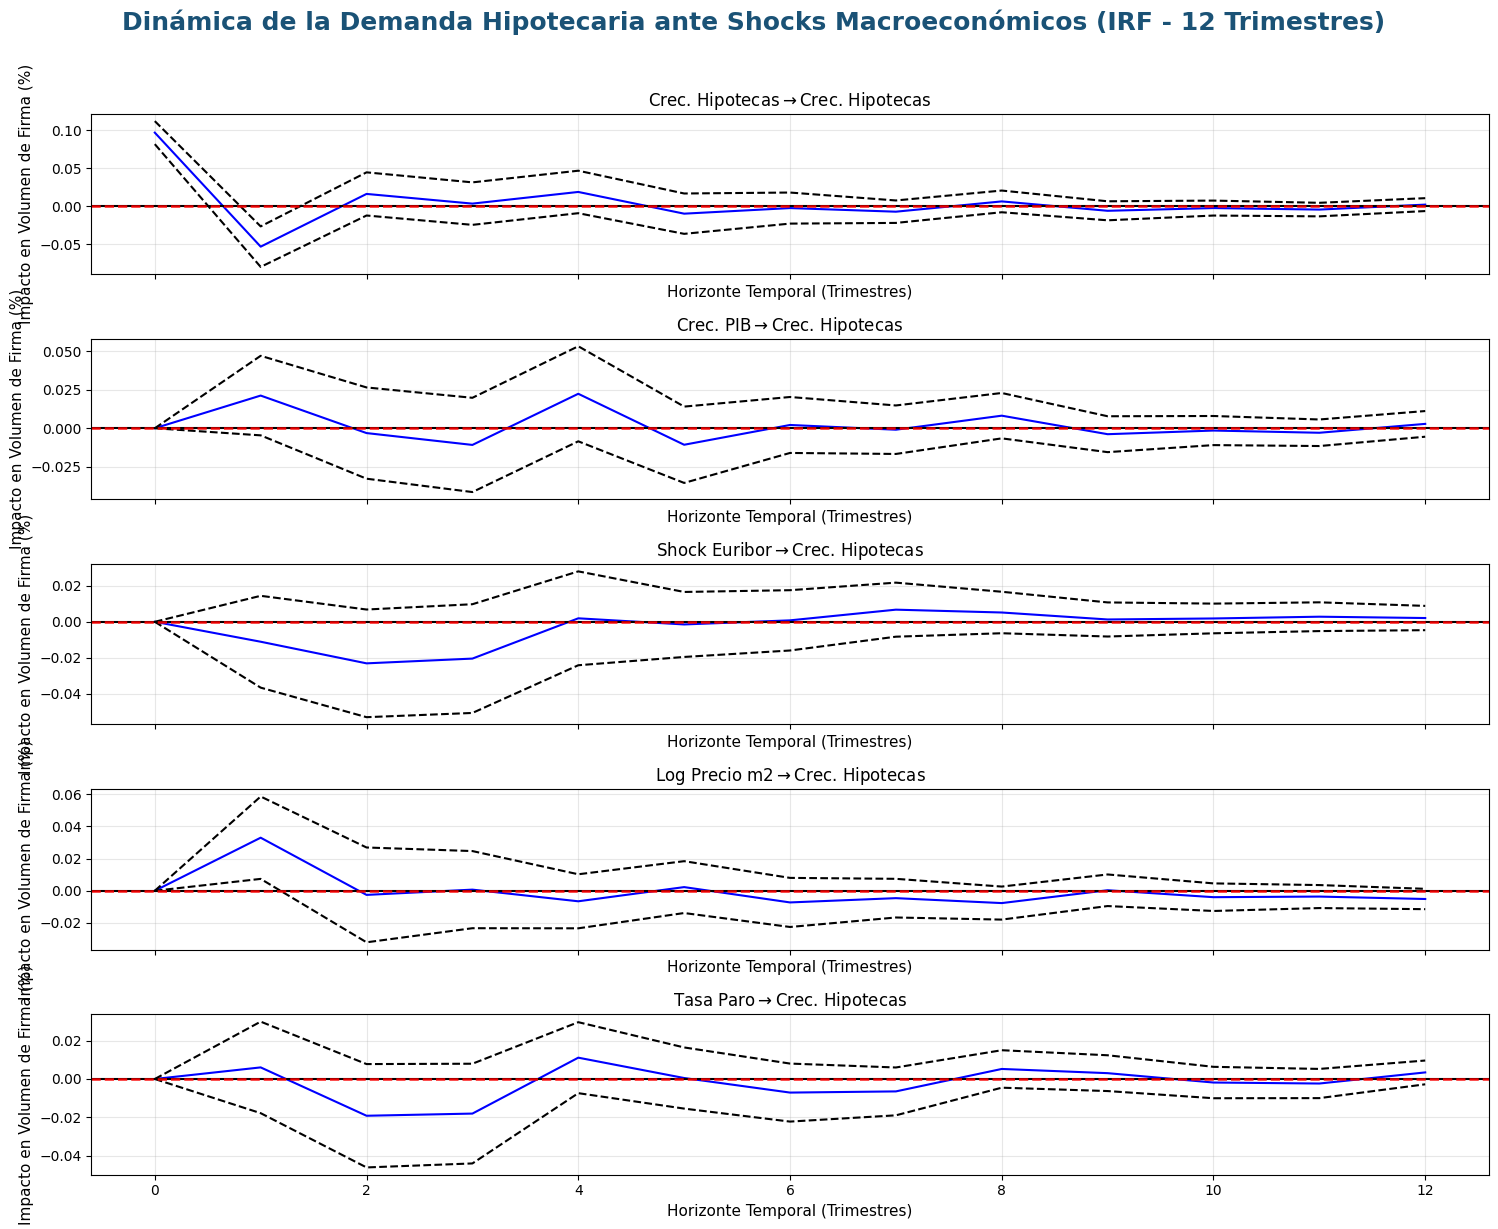

Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# 1. Cargar y agregar datos (Hipotecas a nivel total España)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. DataFrame Estacionario Mixto (VAR) - Metodología Aprobada
df_var = pd.DataFrame(index=df_nacional.index)

# Variables I(1) se pasan a Diferencias (Log/Simples)
df_var['Crec. Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff()
df_var['Crec. PIB'] = np.log(df_nacional['PIB_pc']).diff()
df_var['Shock Euribor'] = df_nacional['Euribor'].diff()

# Variables I(0) se mantienen en Niveles
df_var['Log Precio m2'] = np.log(df_nacional['Precio_m2'])
df_var['Tasa Paro'] = df_nacional['Tasa_Paro']

df_var = df_var.dropna()

# 3. Ajustar Modelo VAR (Memoria de 1 año = Lag 4)
print("Ajustando el VAR y simulando shocks...")
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)

# 4. Generar Funciones Impulso-Respuesta a 3 años (12 trimestres)
irf = res_var.irf(12)

# 5. Dibujar la matriz de gráficas (response='Crec. Hipotecas')
fig = irf.plot(response='Crec. Hipotecas', orth=True, figsize=(15, 12))

# 6. Formato Profesional de Negocio
fig.suptitle("Dinámica de la Demanda Hipotecaria ante Shocks Macroeconómicos (IRF - 12 Trimestres)",
             fontsize=18, fontweight='bold', color='#1a5276', y=1.02)

# Añadir etiquetas claras y el umbral de Cero (Línea Base)
axes = fig.get_axes()
for ax in axes:
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8, alpha=0.9) # Eje Cero
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('Horizonte Temporal (Trimestres)', fontsize=11)
    ax.set_ylabel('Impacto en Volumen de Firma (%)', fontsize=11)

plt.tight_layout()
plt.savefig('matriz_IRF_Hipotecas.png', dpi=300, bbox_inches='tight')
plt.show()

print("Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.")

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR

# 1. Cargar datos
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. EL ORDEN DE CHOLESKY CORRECTO (Macro -> Monetario -> Financiero)
df_var = pd.DataFrame(index=df_nacional.index)
df_var['Crec_PIB'] = np.log(df_nacional['PIB_pc']).diff()          # 1. Lo más lento
df_var['Tasa_Paro'] = df_nacional['Tasa_Paro']                     # 2. Rígido
df_var['Log_Precio_m2'] = np.log(df_nacional['Precio_m2'])         # 3. Precios
df_var['Shock_Euribor'] = df_nacional['Euribor'].diff()            # 4. Monetario
df_var['Crec_Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff() # 5. Lo más reactivo (¡AL FINAL!)
df_var = df_var.dropna()

# 3. Ajustar el VAR y sacar la matriz cruda
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)
irf = res_var.irf(12)

# 4. Extraer Desviaciones Estándar (Tamaño natural del shock)
std_shocks = res_var.resid.std()

# 5. CONSTRUIR LA TABLA ESCALADA (Estilo EViews: Shock de 1%)
idx_hipo = df_var.columns.get_loc('Crec_Hipotecas')
tabla_irf_1pct = pd.DataFrame(index=[f"Trimestre {i}" for i in range(13)])

for col_impulso in df_var.columns:
    idx_impulso = df_var.columns.get_loc(col_impulso)
    # Extraemos el IRF crudo (Impacto sobre Hipotecas)
    respuesta_cruda = irf.orth_irfs[:, idx_hipo, idx_impulso]

    # REESCALAMOS: Dividimos la respuesta por el tamaño del shock para simular un shock de exactamente 1 Unidad (1%)
    respuesta_reescalada = respuesta_cruda / std_shocks[col_impulso]

    tabla_irf_1pct[f"Shock 1% en {col_impulso}"] = respuesta_reescalada

print("--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---")
print(tabla_irf_1pct.round(4).to_string())

--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---
              Shock 1% en Crec_PIB  Shock 1% en Tasa_Paro  Shock 1% en Log_Precio_m2  Shock 1% en Shock_Euribor  Shock 1% en Crec_Hipotecas
Trimestre 0                 0.7418                 0.0135                    -0.5940                    -0.0570                      1.1244
Trimestre 1                 0.5343                -0.0133                    13.9897                    -0.0122                     -0.6723
Trimestre 2                -0.0130                -0.0222                    -3.9287                    -0.1041                      0.1534
Trimestre 3                -0.4508                -0.0249                    -2.4046                    -0.0884                      0.0272
Trimestre 4                 1.1358                 0.0267                    -1.1040                     0.0083                      0.1749
Trimestre 5                -0.5472                -0.0010                     

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


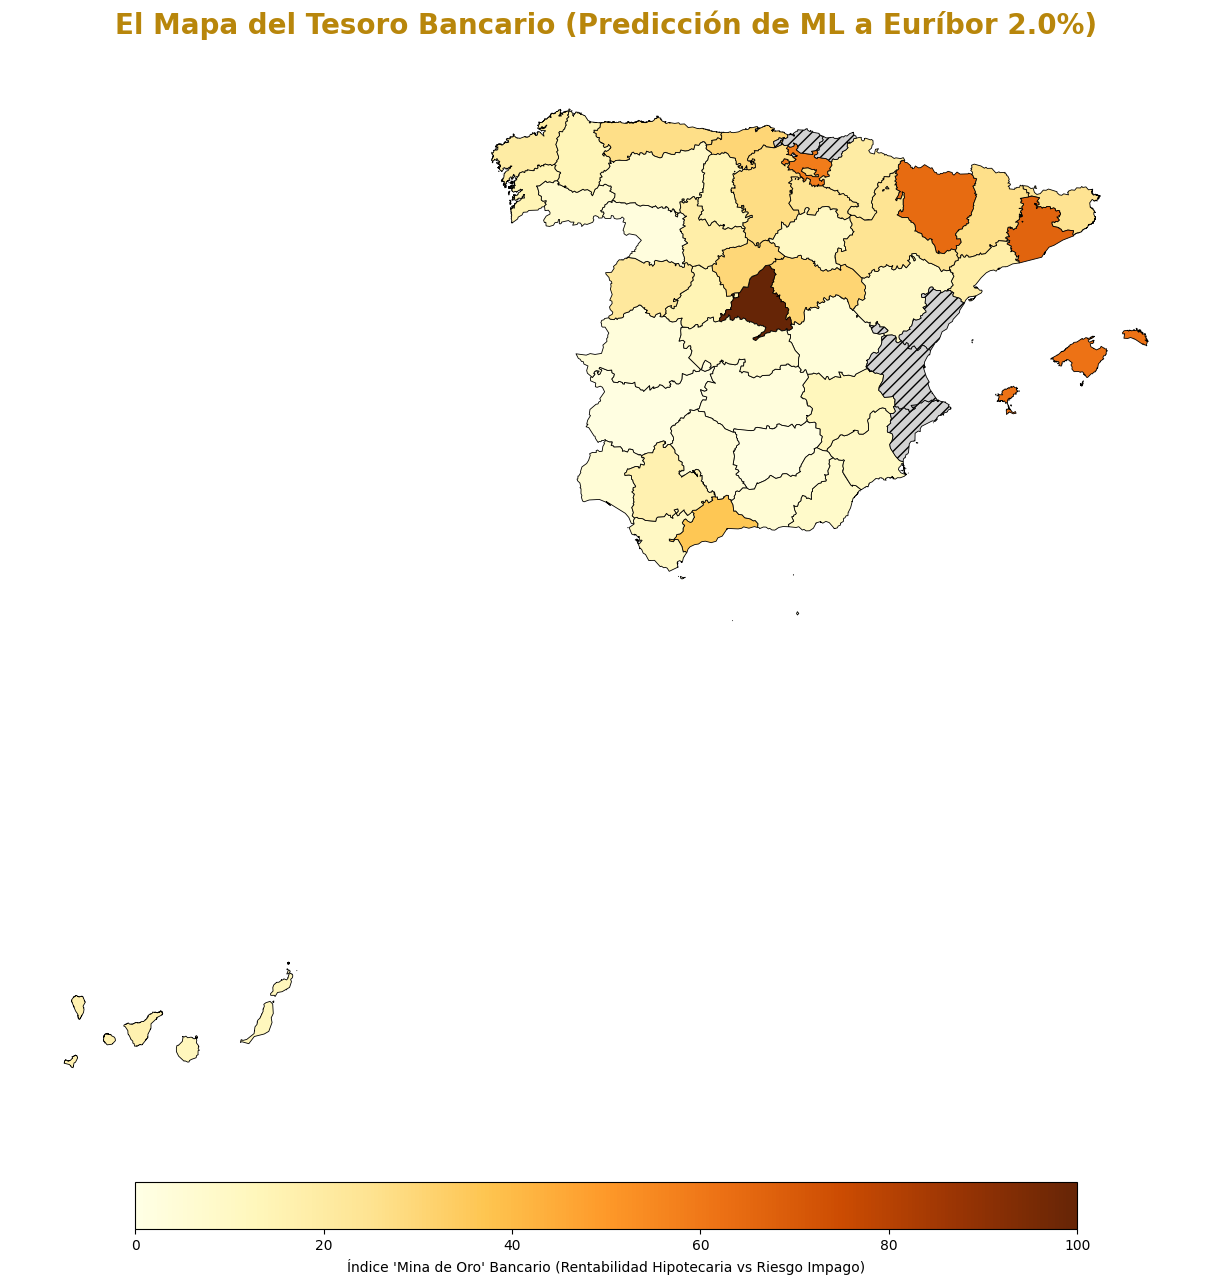

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import unicodedata
from sklearn.ensemble import RandomForestRegressor

# 1. Limpiador de texto para el mapa
def clean_text(text):
    if pd.isna(text): return ""
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# 2. Cargar Datos y Arreglar Nulos
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

# 3. Entrenar el Random Forest
features = ['Precio_m2', 'Euribor', 'tasa_ahorro', 'Spread_Hipotecas',
            'Poblacion', 'Edad_Media', 'Transmisiones_Total',
            'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'Tasa_Paro', 'PIB_pc']
X = df[features]
y = df['Hipotecas_Total']

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

# 4. Construir Escenario de Predicción (Rebaja de Tipos del BCE)
ultimo_trimestre = df['Trimestre'].max()
df_futuro = df[df['Trimestre'] == ultimo_trimestre].copy()
df_futuro['Euribor'] = 2500.0               # Euribor al 2%
df_futuro['Spread_Hipotecas'] = 1000.0      # Margen bancario agresivo

# IA: Predice cuántas hipotecas se firmarán
df_futuro['Prediccion_Hipotecas'] = rf.predict(df_futuro[features])

# 5. Calcular el "Índice Mina de Oro Bancario"
df_futuro['Vol_per_capita'] = df_futuro['Prediccion_Hipotecas'] / df_futuro['Poblacion']
# Volumen x Precio (Ingresos) dividido entre el Paro (Riesgo)
df_futuro['Score_Bruto'] = (df_futuro['Vol_per_capita'] * df_futuro['Precio_m2']) / (df_futuro['Tasa_Paro'] / 100)

# Normalizar de 0 a 100 para pintar el mapa
min_score = df_futuro['Score_Bruto'].min()
max_score = df_futuro['Score_Bruto'].max()
df_futuro['Mina_Oro_Score'] = 100 * (df_futuro['Score_Bruto'] - min_score) / (max_score - min_score)
df_futuro['Provincia_Clean'] = df_futuro['Provincia'].apply(clean_text)

# 6. Cargar la Geometría del Mapa de España
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text)

diccionario_mapa = {
    'illes balears': 'islas baleares', 'alacant / alicante': 'alicante', 'castello / castellon': 'castellon',
    'valencia / valencia': 'valencia', 'araba/alava': 'alava', 'bizkaia': 'vizcaya', 'gipuzkoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid', 'murcia': 'region de murcia', 'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra', 'la coruna': 'a coruna', 'palmas, las': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_futuro, left_on='name_clean', right_on='Provincia_Clean', how='left')

# 7. Renderizar el Mapa Dorado
fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white')
ax.axis('off')

# El mapa de calor dorado (YlOrBr)
merged.plot(column='Mina_Oro_Score',
            cmap='YlOrBr',
            linewidth=0.6,
            ax=ax,
            edgecolor='black',
            legend=True,
            legend_kwds={'label': "Índice 'Mina de Oro' Bancario (Rentabilidad Hipotecaria vs Riesgo Impago)",
                         'orientation': "horizontal",
                         'shrink': 0.6,
                         'pad': 0.05},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})

plt.title("El Mapa del Tesoro Bancario (Predicción de ML a Euríbor 2.0%)",
          fontsize=20, fontweight='bold', color='#B8860B', pad=20)
plt.tight_layout()
plt.savefig('mapa_mina_oro_bancos.png', dpi=300, bbox_inches='tight')
plt.show()